In [ ]:
import uproot
import awkward as ak 
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

paths_water = [    
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-band-blocker-500nm-lp-centered_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-band-blocker-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-500nm-lp-centered_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-mask-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-mask-500nm-lp-centered_lappd_1.root", ]
    

paths_lab = [
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-no-mask-band-blocker-500nm-lp-centered-redo_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-mask-band-blocker-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-mask-band-blocker-500nm-lp-centered_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-no-mask-band-blocker-500nm-lp-centered-redo_lappd_0.root",]
    
    

def n_samples_above_thresh_calc(file_path):
    n_tup = uproot.open(file_path)
    output = n_tup["output;1"]
    event_info = output.arrays(output.keys(), library="ak")
    lcns = event_info['lcns']
    waveforms = event_info['waveforms']
    n_samples_above_thresh = []
    for i in range(len(waveforms)):
        n_above_event = []
        for j in range(len(waveforms[i][0:30])):
            wf = waveforms[i][j][10:-10]
            ped = ak.mean(wf[500:900])
            amp = ak.max(wf) - ped
            thresh = ((ak.max(wf) - ped) * 0.6) + ped 
            crossed = wf > thresh
            above = ak.where(crossed)[0]
            if(amp > 55):
                n_above_event.append(len(above))
            else:
                n_above_event.append(0)
        
        n_samples_above_thresh.append(n_above_event)

    
    return ak.Array(n_samples_above_thresh)

lappd_0_nabove = n_samples_above_thresh_calc(paths_lab[3])
lappd_1_nabove = n_samples_above_thresh_calc(paths_lab[0])


In [46]:
def grouptogrid ( i, j, event):
  ##A  
    if i == 0 and j  ==  0 :
        return 0 
    if i == 1 and j  ==  0 :
        return 0 
    if i == 2 and j  ==  0  :
        return lappd_1_nabove[event][1]
    if i == 3 and j  ==  0  :
         return lappd_1_nabove[event][2]
    if i == 4 and j  ==  0  :
        return lappd_1_nabove[event][3]
    if i == 5 and j  ==  0  :
        return lappd_1_nabove[event][4]
    if i == 6 and j  ==  0  :
        return 0
    if i == 7 and j  ==  0  :
        return 0 

   ##B
    if i == 0 and j  ==  1  :
        return 0
    if i == 1 and j  ==  1  :
        return lappd_1_nabove[event][7]
    if i == 2 and j  ==  1  :
         return lappd_1_nabove[event][8]
    if i == 3 and j  ==  1  :
        return lappd_1_nabove[event][9]
    if i == 4 and j  ==  1  :
        return lappd_1_nabove[event][10]
    if i == 5 and j  ==  1  :
        return lappd_1_nabove[event][11]
    if i == 6 and j  ==  1  :
        return lappd_1_nabove[event][12]
    if i == 7 and j  ==  1  :
        return 0
  ##C  
    if i == 0 and j  ==  2  :
       return lappd_1_nabove[event][14]  
    if i == 1 and j  ==  2  :
        return lappd_1_nabove[event][15] 
    if i == 2 and j  ==  2  :
        return lappd_1_nabove[event][16]
    if i == 3 and j  ==  2  :
         return lappd_1_nabove[event][17]
    if i == 4 and j  ==  2  :
         return lappd_1_nabove[event][18]
    if i == 5 and j  ==  2  :
        return lappd_1_nabove[event][19]
    if i == 6 and j  ==  2  :
         return lappd_1_nabove[event][20]
    if i == 7 and j  ==  2  :
        return lappd_1_nabove[event][21]


##D


    if i == 0 and j  ==  3  :
        return lappd_1_nabove[event][22]
    if i == 1 and j  ==  3  :
        return lappd_1_nabove[event][23]
    if i == 2 and j  ==  3  :
        return lappd_1_nabove[event][24]
    if i == 3 and j  ==  3  :
        return lappd_1_nabove[event][25]
    if i == 4 and j  ==  3  :
        return lappd_0_nabove[event][0]
    if i == 5 and j  ==  3  :
        return lappd_0_nabove[event][1]
    if i == 6 and j  ==  3  :
        return lappd_0_nabove[event][2]
    if i == 7 and j  ==  3  :
         return lappd_0_nabove[event][3]
    ##
    if i == 0 and j  ==  4  :
        return lappd_0_nabove[event][4]
    if i == 1 and j  ==  4  :
        return lappd_0_nabove[event][5]
    if i == 2 and j  ==  4  :
        return lappd_0_nabove[event][6]
    if i == 3 and j  ==  4  :
        return lappd_0_nabove[event][7]
    if i == 4 and j  ==  4  :
         return lappd_0_nabove[event][8]
    if i == 5 and j  ==  4  :
         return lappd_0_nabove[event][9]
    if i == 6 and j  ==  4  :
         return lappd_0_nabove[event][10]
    if i == 7 and j  ==  4  :
        return lappd_0_nabove[event][11]
##F
    if i == 0 and j  ==  5  :
          return lappd_0_nabove[event][12]
    if i == 1 and j  ==  5  :
        return lappd_0_nabove[event][13]
    if i == 2 and j  ==  5  :
        return lappd_0_nabove[event][14]
    if i == 3 and j  ==  5  :
        return lappd_0_nabove[event][15]
    if i == 4 and j  ==  5  :
        return lappd_0_nabove[event][16]
    if i == 5 and j  ==  5  :
        return lappd_0_nabove[event][17]
    if i == 6 and j  ==  5  :
        return lappd_0_nabove[event][18]
    if i == 7 and j  ==  5  :
        return lappd_0_nabove[event][19]

    if i == 0 and j  ==  6  :
        return 0 
    if i == 1 and j  ==  6  :
        return lappd_0_nabove[event][20]
    if i == 2 and j  ==  6  :
        return lappd_0_nabove[event][21]
    if i == 3 and j  ==  6  :
        return lappd_0_nabove[event][23]
    if i == 4 and j  ==  6  :
        return lappd_0_nabove[event][24]
    if i == 5 and j  ==  6  :
        return lappd_0_nabove[event][25]
    if i == 6 and j  ==  6  :
     return lappd_0_nabove[event][26]
    if i == 7 and j  ==  6  :
        return 0
##H
    if i == 0 and j  ==  7  :
        return 0
    if i == 1 and j  ==  7  :
        return 0
    if i == 2 and j  ==  7  :
         return lappd_1_nabove[event][0]
    if i == 3 and j  ==  7  :
        return lappd_1_nabove[event][6]
    if i == 4 and j  ==  7  :
        return lappd_1_nabove[event][13]
    if i == 5 and j  ==  7  :
        return lappd_1_nabove[event][5]
    if i == 6 and j  ==  7  :
        return 0
    if i == 7 and j  ==  7  :
        return 0


def constructgridperevent (event):
    grid = np.zeros((8, 8))
    for i in range(len(grid)):
        for j in range(len(grid[0])):
            grid[i][j] = grouptogrid(i, j, event)
    return grid 

nevents = 500
eventgrid = np.zeros((nevents, 8, 8))
for i in range(nevents):
    eventgrid[i] = constructgridperevent(i)

print(eventgrid[0])


[[0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]]


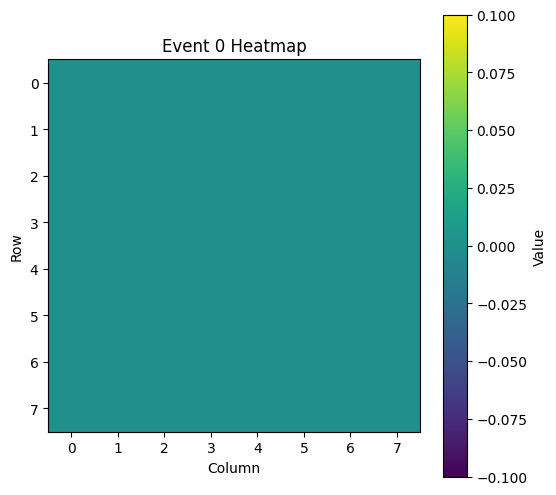

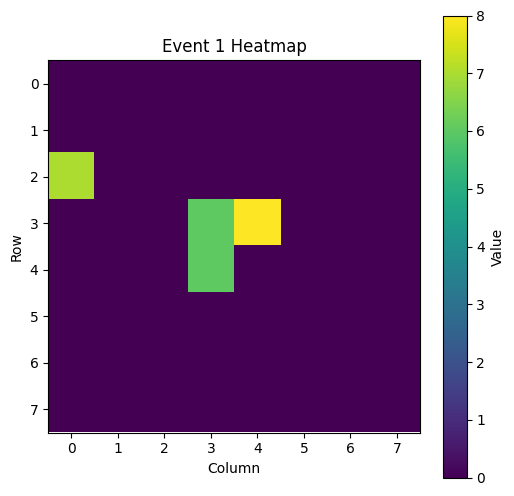

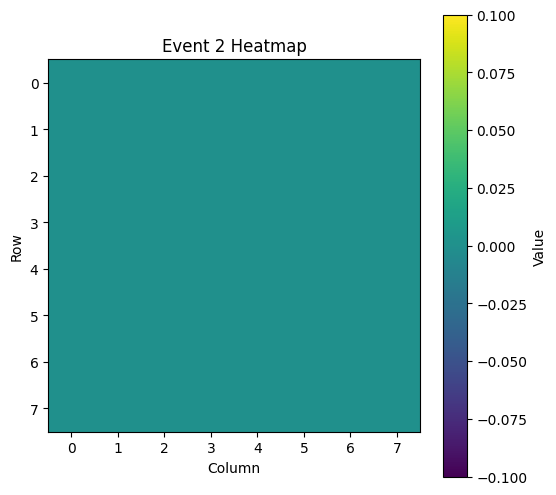

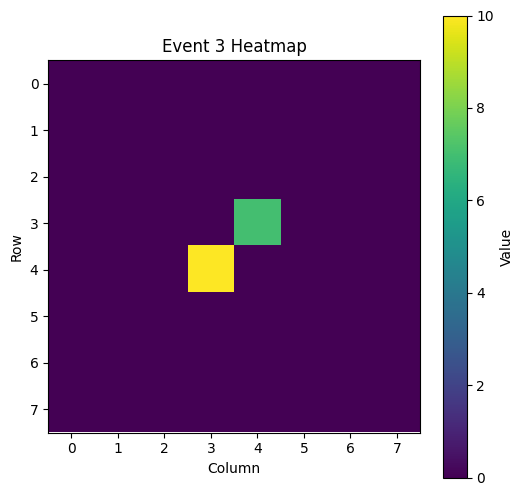

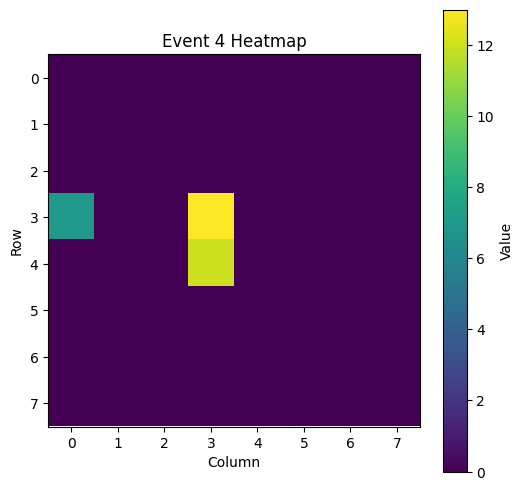

...

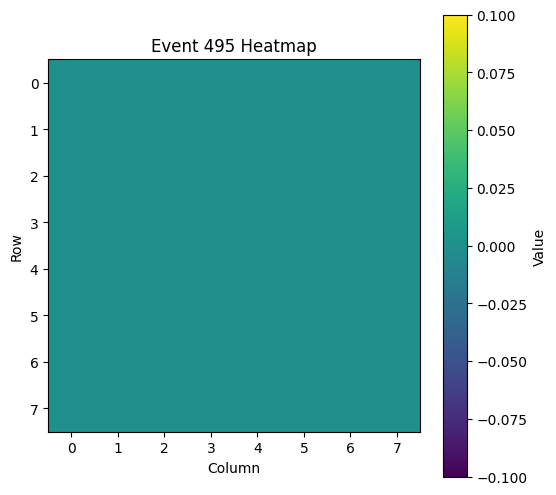

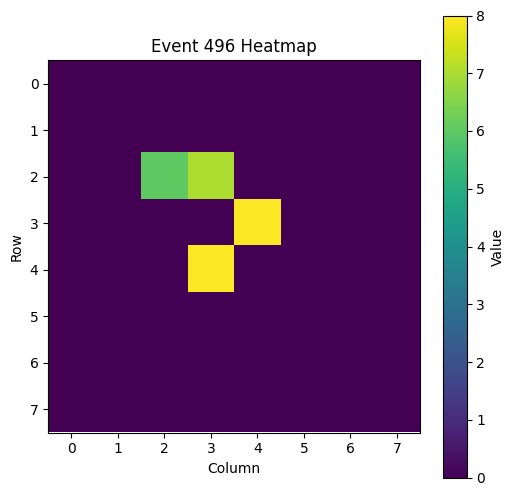

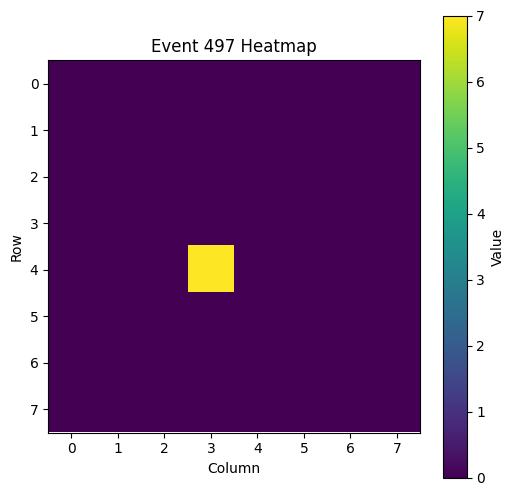

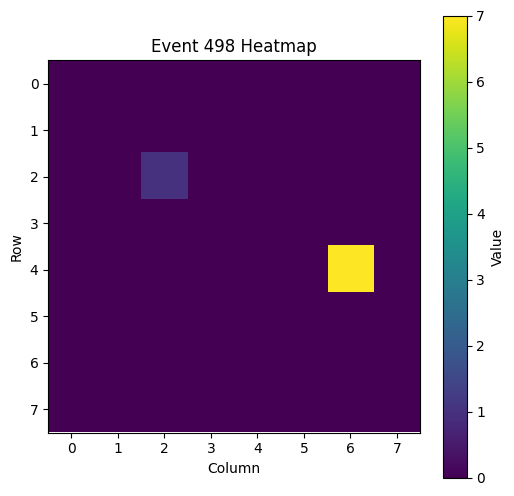

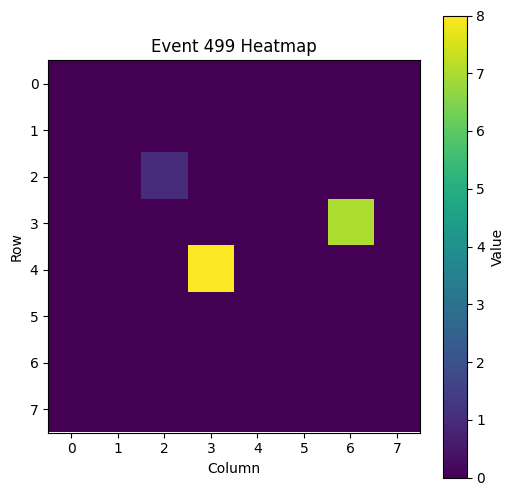

In [47]:
for i in range(nevents):
    plt.figure(figsize=(6,6))
    plt.imshow(eventgrid[i], cmap='viridis', origin='upper')  # row 0 on top
    plt.colorbar(label='Value')
    plt.title(f'Event {i} Heatmap')
    plt.xlabel('Column')
    plt.ylabel('Row')
    plt.show()